# Agent Running Test 
### Prerequisite for LLM used in the agent example
1. Install Ollama from https://ollama.com
2. Start Ollama `ollama run qwen3:0.6b`

### Prerequisites for a Remote VM
1. Start an SSH server (e.g., `openssh-server`) so you can connect to the VM if needed.
2. Install Python virtual environment support (e.g., `python3-venv`).

In [2]:
example_path = 'agent.py'

In [3]:
import requests
from PIL import Image
import matplotlib.pyplot as plt

def im_show(image_url: str):
    if image_url.startswith("http"):
        image = Image.open(requests.get(image_url, stream=True).raw).convert("RGB")
    else:
        image = Image.open(image_url).convert("RGB")

    plt.imshow(image)
    plt.axis("off")
    plt.show()

## Python Interpreter

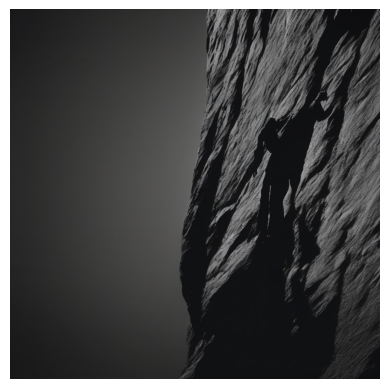

In [4]:
output = !python {example_path}
im_show(output[-1])

## Run the agent and tool teogether locally

In [ ]:
# Removed pip_install parameter from decorators in {example_path}
import ast
import os
import tempfile


with open(example_path, "r") as f:
    source_code = f.read()
    mod = ast.parse(source_code)

# Remove env keyword argument
for node in ast.walk(mod):
    if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
        for dec in node.decorator_list:
            if isinstance(dec, ast.Call):
                dec.keywords = [kw for kw in dec.keywords if kw.arg != "pip_install"]

with tempfile.NamedTemporaryFile("w", delete=False, suffix=".py") as temp_file:
    temp_file.write(ast.unparse(mod))
    temp_file_path = temp_file.name


output = !declagent run {temp_file_path}
for line in output:
    print(line)
im_show(output[-1])
os.unlink(temp_file_path)

## Run the agent locally while executing the tool inside a local Python virtual environment.

Tool 'Text2Image' assigned to Node 'local' 
Installing torch from https://download.pytorch.org/whl/cu124
Looking in indexes: https://download.pytorch.org/whl/cu124
  Using cached https://download.pytorch.org/whl/cu124/torch-2.6.0%2Bcu124-cp313-cp313-win_amd64.whl.metadata (28 kB)
  Using cached filelock-3.20.0-py3-none-any.whl.metadata (2.1 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached https://download.pytorch.org/whl/jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2025.12.0-py3-none-any.whl.metadata (10 kB)
  Using cached https://download.pytorch.org/whl/setuptools-70.2.0-py3-none-any.whl.metadata (5.8 kB)
  Using cached MarkupSafe-2.1.5-py3-none-any.whl
Using cached https://download.pytorch.org/whl/cu124/torch-2.6.0%2Bcu124-cp313-cp313-win_amd64.whl (2532.3 MB)
Using cached filelock-3.20.0-py3-none-any.whl (16 kB)
Using cached fsspec-2025.12.0-py3-none-any.whl (201 kB)
Using cached https://download.pytorch.org/whl/jinja2-3.1

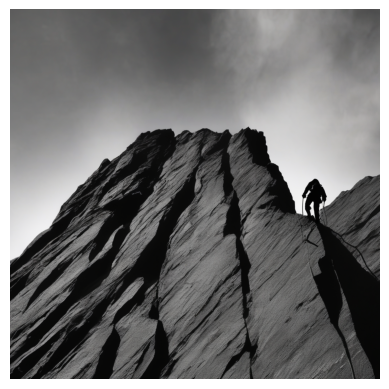

In [6]:
output = !declagent run {example_path}
for line in output:
    print(line)
im_show(output[-1])

## Run the agent locally while executing the tool inside a remote Python virtual environment.

Tool 'Text2Image' assigned to Node 'vm1' 

STARTING REMOTE DEPLOYMENT: Text2Image
Connecting to 172.30.162.209:22 via SSH...
✓ Connected to 172.30.162.209:22 via SSH
Allocating remote port...
✓ Allocated remote port 39817 on 172.30.162.209
Writing code and preparing requirements...
Creating remote directory /tmp/.declagent_cache/Text2Image...
Uploading files via SFTP...
✓ Copied code to remote directory /tmp/.declagent_cache/Text2Image
Creating virtual environment...
✓ Created venv at /tmp/.declagent_cache/Text2Image/.venv
Installing 1 special package(s)...
  Installing torch from https://download.pytorch.org/whl/cu124...
    ✓ Installed torch
Installing packages from requirements.txt...
✓ Installed all requirements
Starting server...
  Waiting for server to start...
  Testing connectivity from local machine to http://172.30.162.209:39817...
  ✓ Server is accessible from local machine at http://172.30.162.209:39817
https://d.tmpfile.link/public/2026-02-07/b8a30666-39c7-40fe-9a65-c1aebb

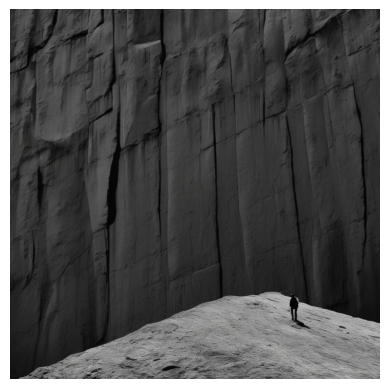

In [8]:
output = !declagent run {example_path} -c "exec_nodes_remote.toml"
for line in output:
    print(line)
im_show(output[-2])

## Clear Cache on nodes

In [ ]:
!declagentlear